# Cybersecurity Intrusion Detection System
## Data Preprocessing on the NSL-KDD Dataset 

## 1. Import libraries and load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

sns.set_theme(style="whitegrid")

In [2]:
from pathlib import Path

dataset_path = Path("NSL_KDD_full_dataset.csv")
if not dataset_path.exists():
    dataset_path = Path("NSL_KDD_full_dataset(1).csv")

data = pd.read_csv(dataset_path)
print("Dataset file:", dataset_path)
print("Dataset shape:", data.shape)
data.head()


Dataset file: NSL_KDD_full_dataset.csv
Dataset shape: (147907, 42)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune
3,0,tcp,http,SF,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


## 2. Inspect and clean the data

In [3]:
print("Missing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())
print("Different attack labels:", data["label"].nunique())
data.info()

Missing values: 0
Duplicate rows: 0
Different attack labels: 40
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 147907 entries, 0 to 147906
Data columns (total 42 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     147907 non-null  int64  
 1   protocol_type                147907 non-null  object 
 2   service                      147907 non-null  object 
 3   flag                         147907 non-null  object 
 4   src_bytes                    147907 non-null  int64  
 5   dst_bytes                    147907 non-null  int64  
 6   land                         147907 non-null  int64  
 7   wrong_fragment               147907 non-null  int64  
 8   urgent                       147907 non-null  int64  
 9   hot                          147907 non-null  int64  
 10  num_failed_logins            147907 non-null  int64  
 11  logged_in                    147907 non-null  int64  

In [4]:
data = data.drop_duplicates()
data = data.drop(columns=["num_outbound_cmds"])

print("Shape after cleaning:", data.shape)

Shape after cleaning: (147907, 41)


In [5]:
dos = ["back","land","neptune","pod","smurf","teardrop","mailbomb","apache2","processtable","udpstorm"]
probe = ["ipsweep","nmap","portsweep","satan","mscan","saint"]
r2l = ["ftp_write","guess_passwd","imap","multihop","phf","spy","warezclient","warezmaster",
       "sendmail","named","snmpgetattack","snmpguess","xlock","xsnoop","worm","httptunnel"]
u2r = ["buffer_overflow","loadmodule","perl","rootkit","ps","sqlattack","xterm"]

data["attack_category"] = "Normal"
data.loc[data["label"].isin(dos), "attack_category"] = "DoS"
data.loc[data["label"].isin(probe), "attack_category"] = "Probe"
data.loc[data["label"].isin(r2l), "attack_category"] = "R2L"
data.loc[data["label"].isin(u2r), "attack_category"] = "U2R"

data["is_attack"] = (data["label"] != "normal").astype(int)

print(data["attack_category"].value_counts())

attack_category
Normal    76967
DoS       52985
Probe     13954
R2L        3882
U2R         119
Name: count, dtype: int64


## 3. Exploratory data analysis (EDA)

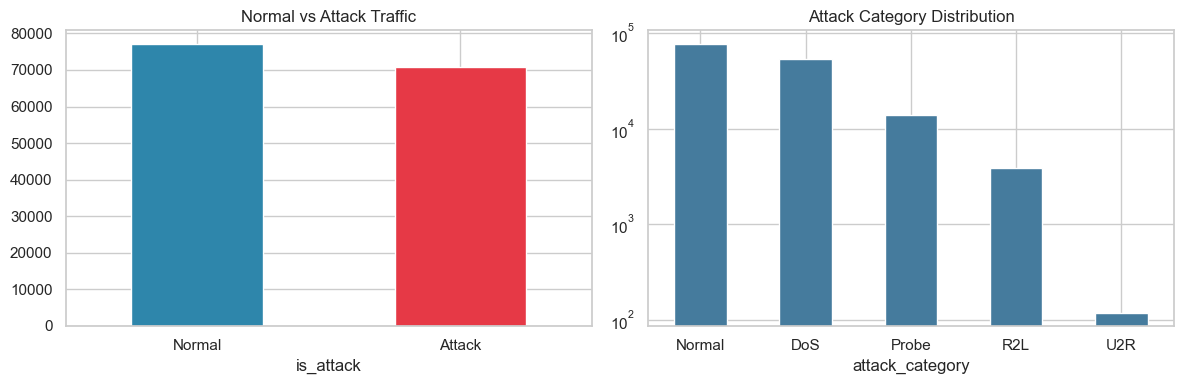

In [6]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
data["is_attack"].map({0: "Normal", 1: "Attack"}).value_counts().plot(kind="bar", color=["#2E86AB", "#E63946"])
plt.title("Normal vs Attack Traffic")
plt.xticks(rotation=0)

plt.subplot(1, 2, 2)
data["attack_category"].value_counts().plot(kind="bar", color="#457B9D")
plt.title("Attack Category Distribution")
plt.yscale("log")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

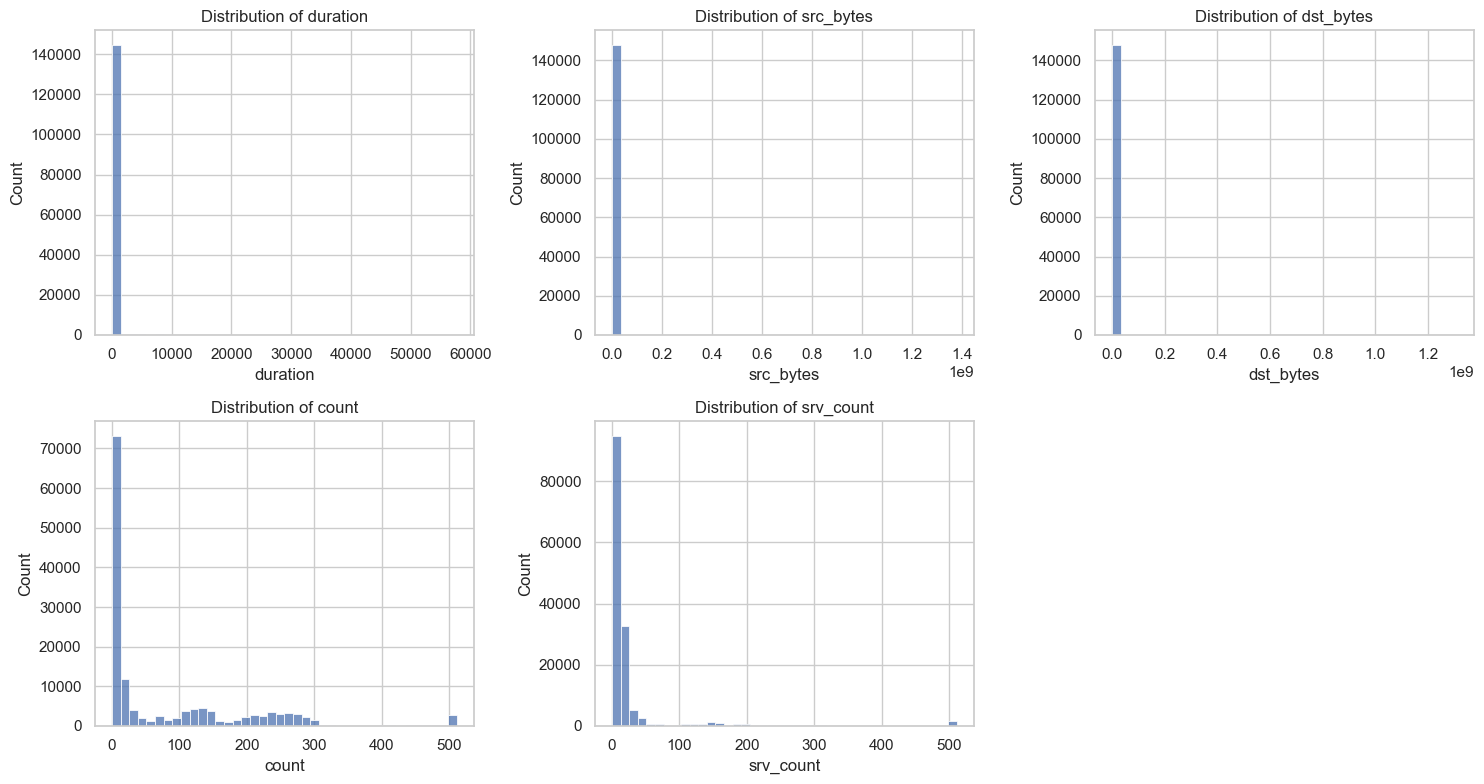

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_features = [
    "duration",
    "src_bytes",
    "dst_bytes",
    "count",
    "srv_count"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_features):
    sns.histplot(data=data, x=col, bins=40, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")

axes[-1].axis("off")
plt.tight_layout()
plt.show()


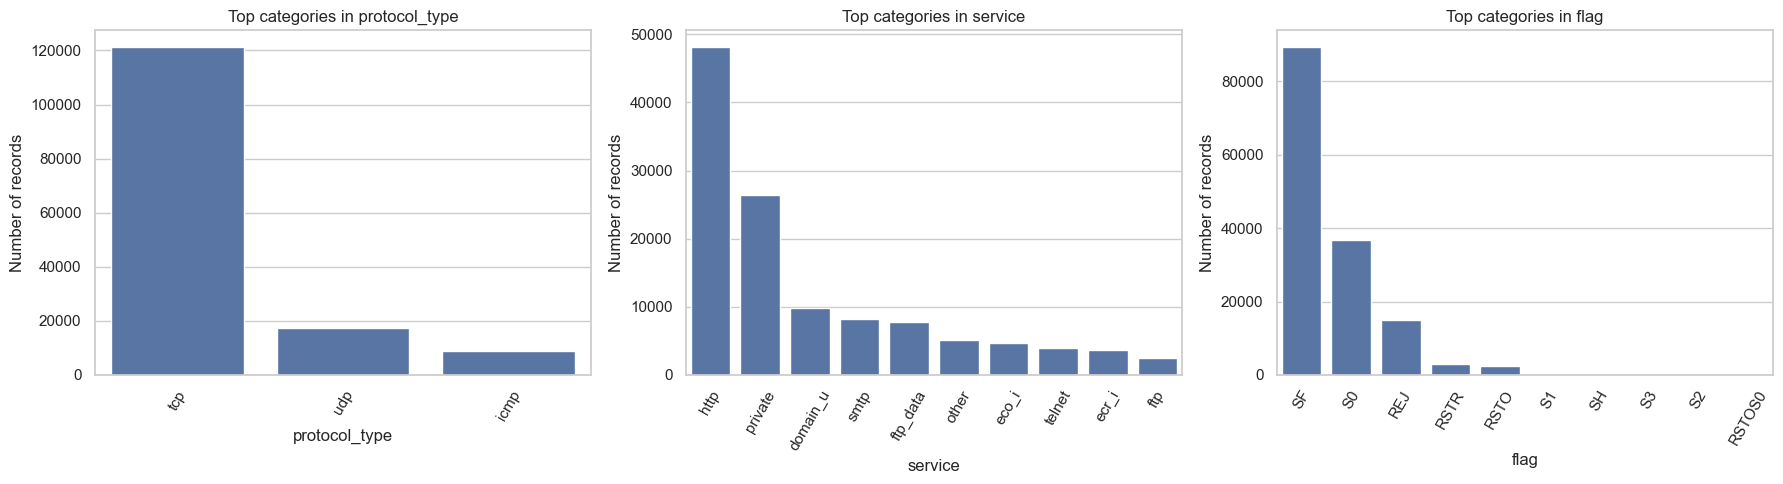

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(
    axes, ["protocol_type", "service", "flag"]
):
    counts = data[col].value_counts().head(10)

    sns.barplot(
        x=counts.index,
        y=counts.values,
        ax=ax
    )

    ax.set_title(f"Top categories in {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of records")
    ax.tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()


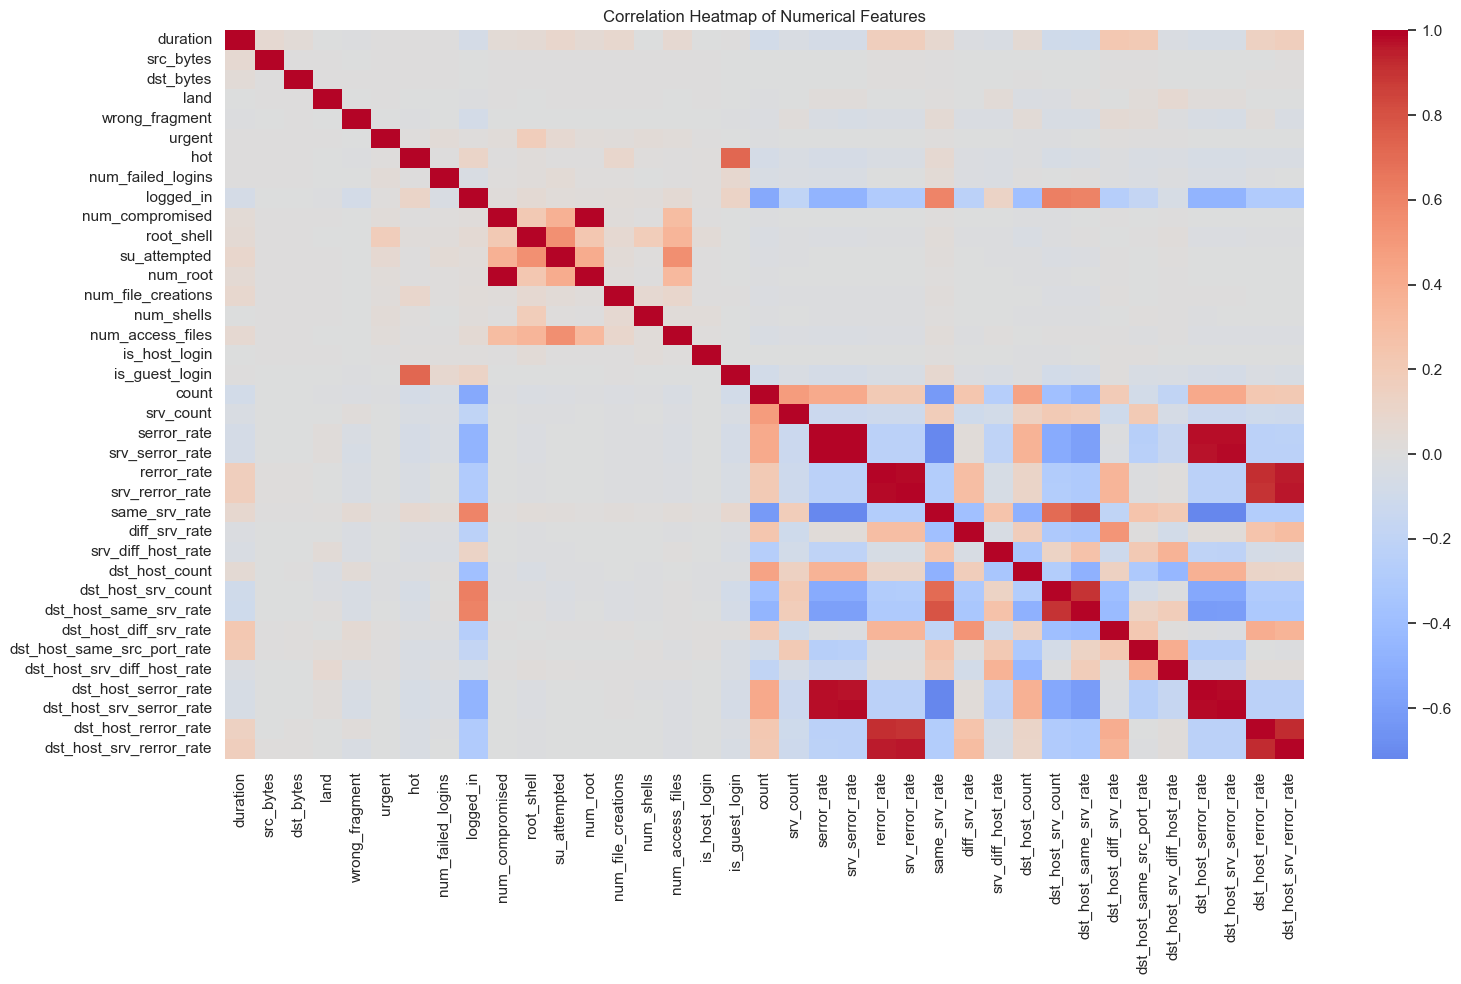

In [9]:
plt.figure(figsize=(16, 10))

corr_data = data.select_dtypes(include=["number"]).drop(columns=["is_attack"], errors="ignore")
corr = corr_data.corr()

sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


## 4. Feature engineering and encoding

In [10]:
duration = data["duration"].replace(0, 1)   # zero se divide na ho

data["total_bytes"] = data["src_bytes"] + data["dst_bytes"]
data["bytes_per_second"] = data["total_bytes"] / duration
data["src_bytes_per_second"] = data["src_bytes"] / duration
data["dst_bytes_per_second"] = data["dst_bytes"] / duration
data["src_dst_byte_ratio"] = (data["src_bytes"] + 1) / (data["dst_bytes"] + 1)
data["connections_per_second"] = data["count"] / duration
data["failed_login_rate"] = data["num_failed_logins"] / (data["count"] + 1)
data["error_rate_total"] = (data["serror_rate"] + data["rerror_rate"]) / 2
data["host_error_rate_total"] = (data["dst_host_serror_rate"] + data["dst_host_rerror_rate"]) / 2

print("Shape with new features:", data.shape)

Shape with new features: (147907, 52)


In [11]:
y = data[["label", "attack_category", "is_attack"]]
X = data.drop(columns=["label", "attack_category", "is_attack"])

X = pd.get_dummies(X, columns=["protocol_type", "service", "flag"], dtype=int)

print("Features after encoding:", X.shape[1])

Features after encoding: 130


## 5. Train/test split and scaling

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y["attack_category"])

X_train = X_train.copy()
X_test = X_test.copy()

print("Train:", X_train.shape)
print("Test :", X_test.shape)
print("\nTrain categories:")
print(y_train["attack_category"].value_counts())

Train: (118325, 130)
Test : (29582, 130)

Train categories:
attack_category
Normal    61573
DoS       42388
Probe     11163
R2L        3106
U2R          95
Name: count, dtype: int64


In [13]:
skewed = ["duration","src_bytes","dst_bytes","total_bytes","bytes_per_second",
          "src_bytes_per_second","dst_bytes_per_second","src_dst_byte_ratio","connections_per_second"]
X_train[skewed] = np.log1p(X_train[skewed])
X_test[skewed] = np.log1p(X_test[skewed])

num_cols = [col for col in X_train.columns if X_train[col].nunique() > 2]

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print("Scaled columns:", len(num_cols))
X_train.head()

Scaled columns: 41


,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,...,flag_REJ,flag_RSTO,flag_RSTOS0,flag_RSTR,flag_S0,flag_S1,flag_S2,flag_S3,flag_SF,flag_SH
70271,-0.243046,1.210940,-0.896973,0,-0.085203,-0.01069,-0.093783,-0.059493,0,-0.010861,...,0,0,0,0,0,0,0,0,1,0
20158,-0.243046,-1.092564,-0.896973,0,-0.085203,-0.01069,-0.093783,-0.059493,0,-0.010861,...,0,0,0,0,1,0,0,0,0,0
140101,-0.243046,0.718092,0.556885,0,-0.085203,-0.01069,-0.093783,-0.059493,1,-0.010861,...,0,0,0,0,0,0,0,0,1,0
121857,-0.243046,0.818852,0.717709,0,-0.085203,-0.01069,-0.093783,-0.059493,1,-0.010861,...,0,0,0,0,0,0,0,0,1,0
3566,-0.243046,0.823014,1.289434,0,-0.085203,-0.01069,-0.093783,-0.059493,1,-0.010861,...,0,0,0,0,0,0,0,0,1,0


## 6. Detect outliers in normal training traffic

In [14]:
from sklearn.ensemble import IsolationForest
import numpy as np


normal_mask = (
    y_train["attack_category"].to_numpy() == "Normal"
)

normal_positions = np.flatnonzero(normal_mask)

outlier_model = IsolationForest(
    contamination=0.01,
    random_state=42
)

outlier_model.fit(X_train.iloc[normal_positions])

predictions = outlier_model.predict(
    X_train.iloc[normal_positions]
)

keep = np.ones(len(X_train), dtype=bool)

keep[normal_positions] = predictions == 1

print("Training rows before removal:", len(X_train))
print("Outliers detected:", np.sum(~keep))

X_train = X_train.iloc[keep].reset_index(drop=True)
y_train = y_train.iloc[keep].reset_index(drop=True)

print("Training rows after removal:", len(X_train))
print("Test rows kept unchanged:", len(X_test))
print("\nTraining class counts after removal:")
print(y_train["attack_category"].value_counts())


Training rows before removal: 118325
Outliers detected: 616
Training rows after removal: 117709
Test rows kept unchanged: 29582

Training class counts after removal:
attack_category
Normal    60957
DoS       42388
Probe     11163
R2L        3106
U2R          95
Name: count, dtype: int64


## 7. Balance the training set with SMOTE

In [15]:
counts = y_train["attack_category"].value_counts()
print("SMOTE se pehle:")
print(counts)

target = int(counts.max() * 0.10)
strategy = {}
for cls in counts.index:
    if counts[cls] < target:
        strategy[cls] = target

smote = SMOTE(sampling_strategy=strategy, random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train["attack_category"])

print("\nSMOTE ke baad:")
print(y_train_smote.value_counts())

SMOTE se pehle:
attack_category
Normal    60957
DoS       42388
Probe     11163
R2L        3106
U2R          95
Name: count, dtype: int64

SMOTE ke baad:
attack_category
Normal    60957
DoS       42388
Probe     11163
R2L        6095
U2R        6095
Name: count, dtype: int64


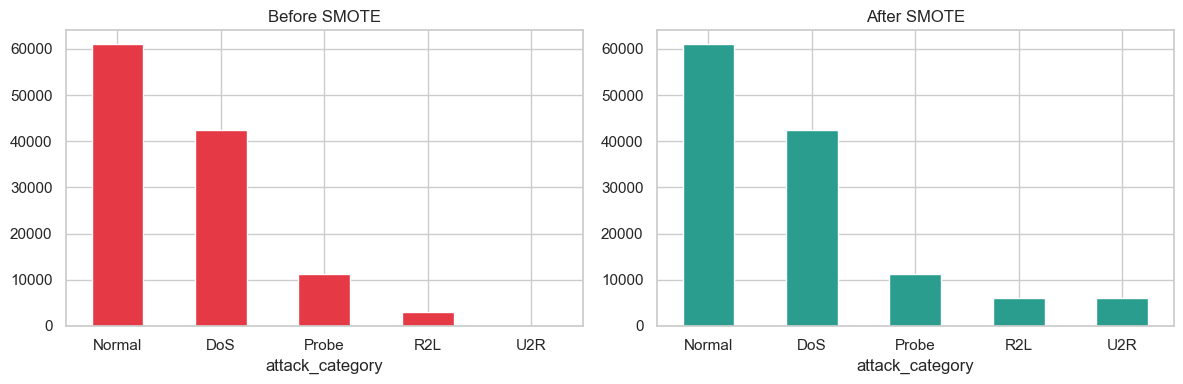

In [16]:
plt.figure(figsize=(12, 4))
order = ["Normal", "DoS", "Probe", "R2L", "U2R"]

plt.subplot(1, 2, 1)
counts.reindex(order).plot(kind="bar", color="#E63946")
plt.title("Before SMOTE")
plt.xticks(rotation=0)

plt.subplot(1, 2, 2)
y_train_smote.value_counts().reindex(order).plot(kind="bar", color="#2A9D8F")
plt.title("After SMOTE")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

## 8. Save the processed datasets

In [17]:
train_out = X_train.copy()
train_out["attack_category"] = y_train["attack_category"].values
train_out["is_attack"] = y_train["is_attack"].values

test_out = X_test.copy()
test_out["attack_category"] = y_test["attack_category"].values
test_out["is_attack"] = y_test["is_attack"].values

smote_out = X_train_smote.copy()
smote_out["attack_category"] = y_train_smote.values
smote_out["is_attack"] = (smote_out["attack_category"] != "Normal").astype(int)

train_out.to_csv("train_processed.csv", index=False)
test_out.to_csv("test_processed.csv", index=False)
smote_out.to_csv("train_processed_smote.csv", index=False)

print("Saved train_processed.csv      :", train_out.shape)
print("Saved test_processed.csv       :", test_out.shape)
print("Saved train_processed_smote.csv:", smote_out.shape)

Saved train_processed.csv      : (117709, 132)
Saved test_processed.csv       : (29582, 132)
Saved train_processed_smote.csv: (126698, 132)
